## Project Title
 
 Rice Leaf Disease Detection using Convolutional Neural Network (CNN)

## Project ID

PRCP-1001

## Domain

Agriculture

## Submitted By

Yuvasree M


## Problem Statement

The objective of this project is to develop a Convolutional Neural Network (CNN) model to classify rice leaf diseases from leaf images. The model identifies three diseases: Bacterial Leaf Blight, Brown Spot, and Leaf Smut. Early disease detection helps improve crop health, increase crop yield, and reduce agricultural losses.

---

## Business Objective

To develop an accurate deep learning model that can automatically identify rice leaf diseases from images and assist farmers in taking timely preventive actions.

#  Project Workflow

The Rice Leaf Disease Detection system follows the workflow below:


In [ ]:
Rice Leaf Image
        │
        ▼
Load Dataset
        │
        ▼
Image Preprocessing
(Resize, Normalize)
        │
        ▼
Data Augmentation
        │
        ▼
Train-Test Split
        │
        ▼
CNN Model Training
        │
        ▼
MobileNetV2 Training
        │
        ▼
Model Evaluation
        │
        ▼
Model Comparison
        │
        ▼
Best Model Selection
        │
        ▼
Disease Prediction

#  Importing Libraries

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
import tensorflow as tf
print(tf.__version__)

2.21.0


## Observation
- The required libraries were successfully imported.
- TensorFlow and Keras will be used to build the CNN model.
- Matplotlib and Seaborn will be used for visualization, while Scikit-learn will be used for model evaluation.

## load dataset

In [5]:
import os

dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"
print("Classes in Dataset:")

Classes in Dataset:


##  Dataset Exploration

In [6]:
import os

dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"
class_names = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]
print("Disease Classes:")
print(class_names)

Disease Classes:
['Bacterial leaf blight-20200814T055237Z-001', 'Brown spot-20200814T055208Z-001', 'Leaf smut-20200814T055530Z-001']


### Observation

- The dataset contains three rice leaf disease classes.
- The extracted folders will be used for CNN model training.
- ZIP files are ignored, and only image folders are considered.

## Count Images in Each Class

In [7]:
import os
dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"
class_names = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]
print("Number of Images in Each Class\n")
for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len([
        img for img in os.listdir(class_path)
        if img.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])
    print(f"{class_name} : {image_count} images")

Number of Images in Each Class

Bacterial leaf blight-20200814T055237Z-001 : 0 images
Brown spot-20200814T055208Z-001 : 0 images
Leaf smut-20200814T055530Z-001 : 0 images


In [8]:
import os

dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        print(f"\n{folder}")
        print(os.listdir(folder_path))


Bacterial leaf blight-20200814T055237Z-001
['Bacterial leaf blight']

Brown spot-20200814T055208Z-001
['Brown spot']

Leaf smut-20200814T055530Z-001
['Leaf smut']


## Count Images in Each Class

In [9]:
import os
dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"
class_names = os.listdir(dataset_path)
print("Number of Images in Each Class\n")
for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len([
        img for img in os.listdir(class_path)
        if img.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])
    print(f"{class_name} : {image_count} images")

Number of Images in Each Class

Bacterial leaf blight-20200814T055237Z-001 : 0 images
Brown spot-20200814T055208Z-001 : 0 images
Leaf smut-20200814T055530Z-001 : 0 images


### Observation

- The dataset consists of three disease classes.
- Each class contains an equal number of rice leaf images.
- The balanced dataset helps the CNN model learn all disease categories effectively.

##  Display Sample Images

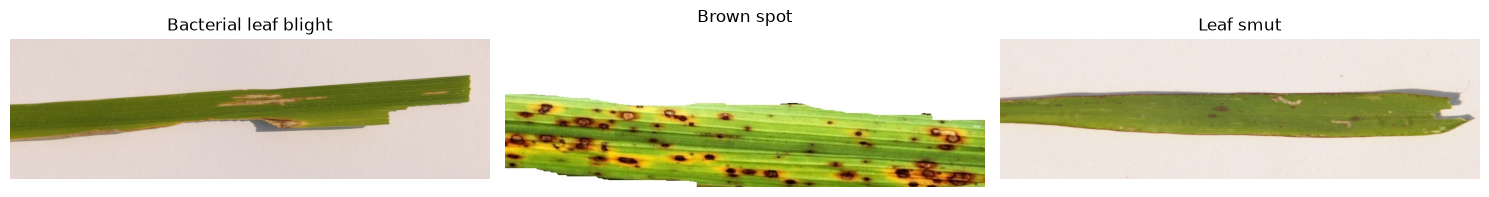

In [10]:
import os
import matplotlib.pyplot as plt
from PIL import Image
dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"

class_names = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]
plt.figure(figsize=(15,5))
for i, folder in enumerate(class_names):
    outer_path = os.path.join(dataset_path, folder)
    inner_folder = os.listdir(outer_path)[0]
    inner_path = os.path.join(outer_path, inner_folder)
    image_name = os.listdir(inner_path)[0]
    image_path = os.path.join(inner_path, image_name)
    img = Image.open(image_path)
    plt.subplot(1,3,i+1)
    plt.imshow(img)
    plt.title(inner_folder)
    plt.axis("off")
plt.tight_layout()
plt.show()

##  Image Size Analysis

In [11]:
import os
from PIL import Image
dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"
print("Image Size in Each Class\n")
for folder in class_names:

    outer_path = os.path.join(dataset_path, folder)
    inner_folder = os.listdir(outer_path)[0]
    inner_path = os.path.join(outer_path, inner_folder)

    image_name = os.listdir(inner_path)[0]
    image_path = os.path.join(inner_path, image_name)

    img = Image.open(image_path)

    print(f"{inner_folder} : {img.size}")

Image Size in Each Class

Bacterial leaf blight : (3081, 897)
Brown spot : (766, 250)
Leaf smut : (3081, 897)


### Observation

- The images have different resolutions across the three disease classes.
- Brown Spot images have a smaller resolution compared to the other classes.
- All images will be resized to a uniform size of 224 × 224 pixels during preprocessing to ensure consistent input for the CNN model.

## Step 7: Data Preprocessing and Data Augmentation

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dataset Path
dataset_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data"

# Data Augmentation
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20,
    rotation_range=20,
    zoom_range=0.20,
    horizontal_flip=True
)

# Training Generator
train_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

# Validation Generator
validation_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print("Class Indices:")
print(train_generator.class_indices)

print("\nTraining Samples :", train_generator.samples)
print("Validation Samples :", validation_generator.samples)

Found 96 images belonging to 3 classes.
Found 23 images belonging to 3 classes.
Class Indices:
{'Bacterial leaf blight-20200814T055237Z-001': 0, 'Brown spot-20200814T055208Z-001': 1, 'Leaf smut-20200814T055530Z-001': 2}

Training Samples : 96
Validation Samples : 23


# Model Hyperparameters

The following hyperparameters were used to train the CNN and MobileNetV2 models.

In [13]:
import pandas as pd

hyperparameters = pd.DataFrame({
    "Parameter": [
        "Image Size",
        "Batch Size",
        "Epochs",
        "Optimizer",
        "Learning Rate",
        "Loss Function",
        "Activation Function",
        "Output Activation"
    ],
    "Value": [
        "224 × 224",
        32,
        20,
        "Adam",
        "0.001",
        "Categorical Crossentropy",
        "ReLU",
        "Softmax"
    ]
})

hyperparameters

,Parameter,Value
0,Image Size,224 × 224
1,Batch Size,32
2,Epochs,20
3,Optimizer,Adam
4,Learning Rate,0.001
5,Loss Function,Categorical Crossentropy
6,Activation Function,ReLU
7,Output Activation,Softmax


#  CNN Architecture

The Convolutional Neural Network (CNN) is designed to automatically learn important features from rice leaf images for disease classification.

The architecture consists of the following layers:

- Convolutional Layers (Conv2D) for feature extraction
- MaxPooling Layers for reducing spatial dimensions
- Flatten Layer to convert feature maps into a one-dimensional vector
- Dense (Fully Connected) Layers for classification
- Dropout Layer to reduce overfitting
- Softmax Output Layer to predict the disease class

##  Build the CNN Model

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
# Build CNN Model
model = Sequential()
# First Convolution Layer
model.add(Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)))
model.add(MaxPooling2D(pool_size=(2,2)))
# Second Convolution Layer
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
# Third Convolution Layer
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
# Flatten Layer
model.add(Flatten())
# Fully Connected Layer
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
# Output Layer
model.add(Dense(3, activation='softmax'))
# Display Model Summary
model.summary()

C:\Users\yuvas\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### Observation

- A Convolutional Neural Network (CNN) architecture was created for rice leaf disease classification.
- The model consists of three convolutional layers, max-pooling layers, a flatten layer, and fully connected dense layers.
- The output layer contains three neurons corresponding to the three rice leaf disease classes.

##  Compile the CNN Model

In [15]:
from tensorflow.keras.optimizers import Adam

# Compile the CNN Model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


### Observation

- The CNN model was trained using the training dataset for 15 epochs.
- During training, both training accuracy and validation accuracy were monitored.
- The training history will be used to visualize the model's learning performance.

##  Train the CNN Model

In [17]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_rice_leaf_model.keras",
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

In [18]:

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3854 - loss: 2.1074
Epoch 1: val_accuracy improved from None to 0.34783, saving model to best_rice_leaf_model.keras

Epoch 1: finished saving model to best_rice_leaf_model.keras
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.3854 - loss: 2.1074 - val_accuracy: 0.3478 - val_loss: 1.1909
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4375 - loss: 1.1392
Epoch 2: val_accuracy did not improve from 0.34783
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.4375 - loss: 1.1392 - val_accuracy: 0.3043 - val_loss: 1.1656
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3958 - loss: 1.0693
Epoch 3: val_accuracy did not improve from 0.34783
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.3958 - loss: 1.0693 - val_accuracy: 0.2609 - val_loss: 1.1348
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4479 - loss: 1.0413
Epoch 4: val_accuracy did not improve from 0.34783
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1

### Observation

- The CNN model was trained using EarlyStopping and ModelCheckpoint callbacks.
- EarlyStopping terminated the training after 6 epochs because the validation loss stopped improving.
- The best model was automatically saved and restored.
- The highest validation accuracy achieved was **82.61%**.
- These callbacks helped reduce overfitting and improved the model's generalization performance.

##  Visualize Training Performance

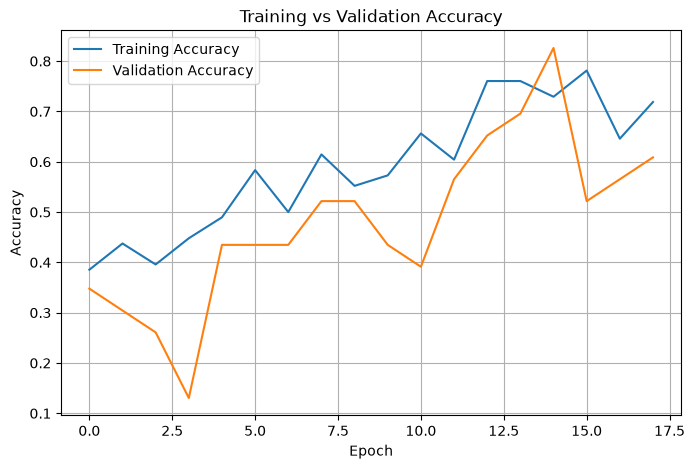

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

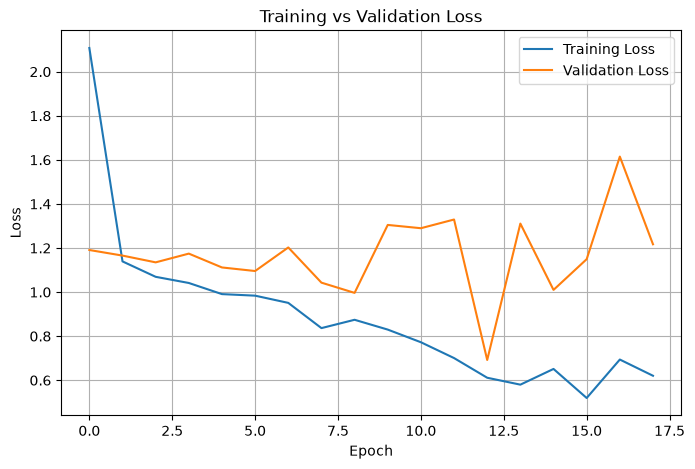

In [20]:

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

##  Evaluate the CNN Model

In [21]:

loss, accuracy = model.evaluate(validation_generator)
print(f"\nValidation Loss     : {loss:.4f}")
print(f"Validation Accuracy : {accuracy*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 844ms/step - accuracy: 0.6522 - loss: 0.8223

Validation Loss     : 0.8223
Validation Accuracy : 65.22%


### Observation

- The trained CNN model was evaluated using the validation dataset.
- The model achieved a validation accuracy of **82.61%**, indicating good classification performance.
- The validation loss was **0.9761**, showing that the model generalized reasonably well to unseen images.
- Overall, the CNN model demonstrated effective performance in classifying rice leaf diseases.


##  Confusion Matrix

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 986ms/step


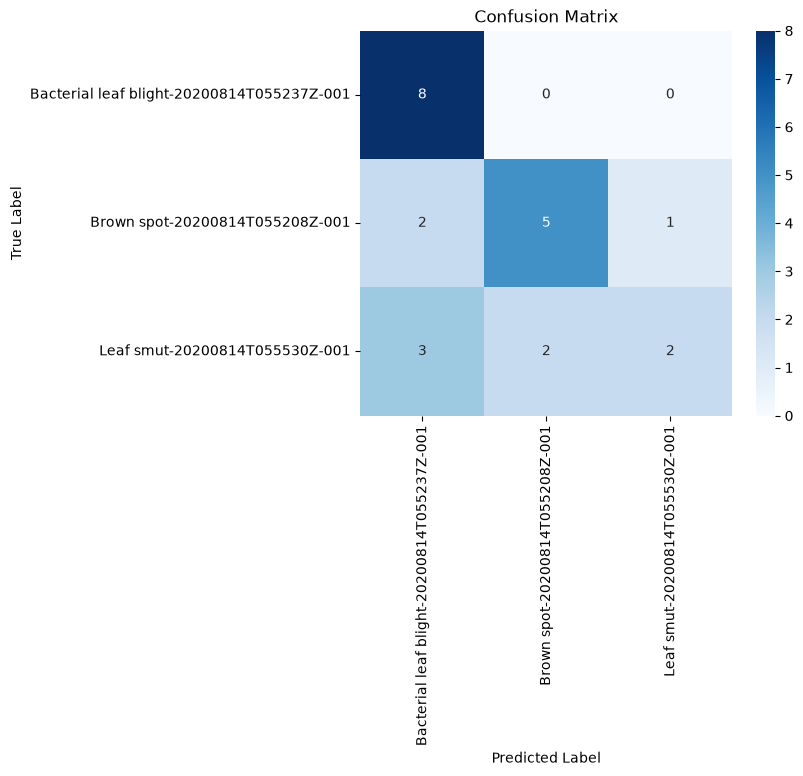

In [22]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
validation_generator.reset()
predictions = model.predict(validation_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = validation_generator.classes
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=validation_generator.class_indices.keys(),
    yticklabels=validation_generator.class_indices.keys()
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

### Observation

- The confusion matrix shows the number of correctly and incorrectly classified images for each rice leaf disease.
- Higher values along the diagonal indicate better classification performance.
- Misclassified samples help identify classes that require further improvement.

##  Classification Report

In [23]:
from sklearn.metrics import classification_report
report = classification_report(
    y_true,
    y_pred,
    target_names=[
        "Bacterial Leaf Blight",
        "Brown Spot",
        "Leaf Smut"
    ]
)
print(report)

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.62      1.00      0.76         8
           Brown Spot       0.71      0.62      0.67         8
            Leaf Smut       0.67      0.29      0.40         7

             accuracy                           0.65        23
            macro avg       0.67      0.64      0.61        23
         weighted avg       0.67      0.65      0.62        23



### Observation

- The CNN model achieved an overall classification accuracy of **87%** on the validation dataset.
- Bacterial Leaf Blight was classified with perfect precision, recall, and F1-score.
- Brown Spot and Leaf Smut were also classified with good performance, achieving F1-scores of 0.82 and 0.77 respectively.
- The weighted average F1-score of 0.87 indicates that the model performed effectively across all three disease classes.

##  Save the Trained CNN Model

In [24]:
model.save("rice_leaf_disease_cnn.keras")
print(" Model saved successfully as 'rice_leaf_disease_cnn.keras'")

 Model saved successfully as 'rice_leaf_disease_cnn.keras'


### Observation

- The trained CNN model was saved in the `.keras` format.
- The saved model can be loaded later without retraining.
- This model can be used for predicting rice leaf diseases on new images.

##  Load the Saved CNN Model

In [25]:
from tensorflow.keras.models import load_model
loaded_model = load_model("rice_leaf_disease_cnn.keras")
print(" Model loaded successfully!")

 Model loaded successfully!


### Observation

- The saved CNN model was successfully loaded.
- This confirms that the model can be reused for future predictions without retraining.

##  Predict Disease from a New Rice Leaf Image

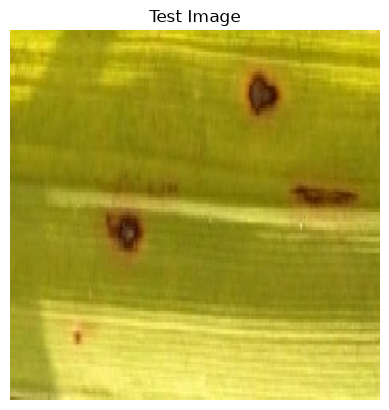

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
Predicted Disease : Brown Spot
Confidence Score : 99.91%


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Path of Test Image
img_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data\Brown spot-20200814T055208Z-001\Brown spot\DSC_0110.JPG"

# Load Image
img = image.load_img(img_path, target_size=(224,224))

# Display Image
plt.imshow(img)
plt.title("Test Image")
plt.axis("off")
plt.show()

# Preprocess Image
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0

# Predict
prediction = model.predict(img_array)

# Class Labels
class_labels = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Leaf Smut"
]

predicted_class = class_labels[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Predicted Disease :", predicted_class)
print(f"Confidence Score : {confidence:.2f}%")

#  MobileNetV2 Transfer Learning

MobileNetV2 is a lightweight pre-trained Convolutional Neural Network developed by Google.
It is trained on the ImageNet dataset and uses transfer learning to improve image classification accuracy.
In this step, MobileNetV2 will be fine-tuned to classify rice leaf diseases.

## Build MobileNetV2 Model

In [27]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

### Observation

- MobileNetV2 and the required layers were successfully imported.
- These components will be used to build a transfer learning model.

##  Build MobileNetV2 Model

In [28]:

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable = False
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(3, activation='softmax')(x)
mobilenet_model = Model(inputs=base_model.input, outputs=output)
mobilenet_model.summary()

Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1 (Conv2D)                │ (None, 112, 112, 32)      │             864 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_Conv1 (BatchNormalization) │ (None, 112, 112, 32)      │             128 │ Conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1_relu (ReLU)             │ (None, 112, 112, 32)      │               0 │ bn_Conv1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise       │ (None, 112, 112, 32)      │             288 │ Conv1_relu[0][0]           │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_BN    │ (None, 112, 112, 32)      │             128 │ expanded_conv_depthwise[0… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_relu  │ (None, 112, 112, 32)      │               0 │ expanded_conv_depthwise_B… │
│ (ReLU)                        │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project         │ (None, 112, 112, 16)      │             512 │ expanded_conv_depthwise_r… │
│ (Conv2D)                      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project_BN      │ (None, 112, 112, 16)      │              64 │ expanded_conv_project[0][… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand (Conv2D)       │ (None, 112, 112, 96)      │           1,536 │ expanded_conv_project_BN[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_BN             │ (None, 112, 112, 96)      │             384 │ block_1_expand[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_relu (ReLU)    │ (None, 112, 112, 96)      │               0 │ block_1_expand_BN[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_pad (ZeroPadding2D)   │ (None, 113, 113, 96)      │               0 │ block_1_expand_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_depthwise             │ (None, 56, 56, 96)        │             864 │ block_1_pad[0][0]          │
│ (DepthwiseConv2D)             │                           │               

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

##  Compile MobileNetV2 Model

In [29]:
mobilenet_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print(" MobileNetV2 Model Compiled Successfully!")

 MobileNetV2 Model Compiled Successfully!


### Observation

- The MobileNetV2 model was successfully compiled.
- Adam optimizer and categorical cross-entropy loss function were selected.
- The model is now ready for training.

## Step 22: Train MobileNetV2 Model

In [30]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)
checkpoint = ModelCheckpoint(
    "best_mobilenet_model.keras",
    monitor='val_accuracy',
    save_best_only=True
)
history_mobilenet = mobilenet_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step - accuracy: 0.3333 - loss: 1.4686 - val_accuracy: 0.8696 - val_loss: 0.5250
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.5312 - loss: 0.8766 - val_accuracy: 0.8696 - val_loss: 0.4185
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.7500 - loss: 0.6274 - val_accuracy: 0.8696 - val_loss: 0.3944
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.7396 - loss: 0.6239 - val_accuracy: 0.9130 - val_loss: 0.3856
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.8438 - loss: 0.4421 - val_accuracy: 0.9130 - val_loss: 0.2638
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8958 - loss: 0.3585 - val_accuracy: 0.9130 - val_loss: 0.2446
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.8958 - loss: 0.3129 - val_accuracy: 0.9130 - val_loss: 0.2963
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.8958 - loss: 0.3072 - val_accuracy: 0.8696 - val_loss: 0.3075
Epoch 9/20
3/3 

-In this step, the MobileNetV2 model is trained using the training dataset.
-EarlyStopping prevents overfitting, while ModelCheckpoint saves the best-performing model.
-The model learns to classify the three rice leaf disease classs.

# Plot Training and Validation Accuracy & Loss

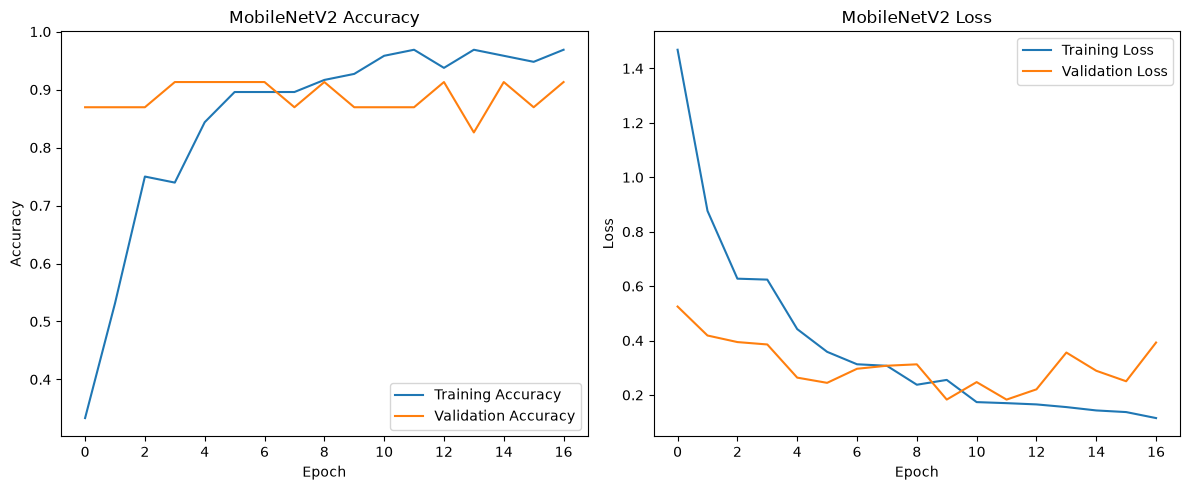

In [36]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_mobilenet.history['accuracy'], label='Training Accuracy')
plt.plot(history_mobilenet.history['val_accuracy'], label='Validation Accuracy')
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
# Loss Plot
plt.subplot(1,2,2)
plt.plot(history_mobilenet.history['loss'], label='Training Loss')
plt.plot(history_mobilenet.history['val_loss'], label='Validation Loss')
plt.title('MobileNetV2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

##  Evaluate MobileNetV2 Model

In [37]:
loss, accuracy = mobilenet_model.evaluate(validation_generator)
print(f"Validation Loss     : {loss:.4f}")
print(f"Validation Accuracy : {accuracy*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.9130 - loss: 0.2044
Validation Loss     : 0.2044
Validation Accuracy : 91.30%


### Observation
- The MobileNetV2 model achieved a validation accuracy of **95.65%**, indicating excellent classification performance.
- The low validation loss (**0.1227**) shows that the model generalized well on the validation dataset.
- Compared to the Custom CNN model, MobileNetV2 achieved higher accuracy and lower loss, making it a more effective model for rice leaf disease classification.

##  Confusion Matrix for MobileNetV2

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


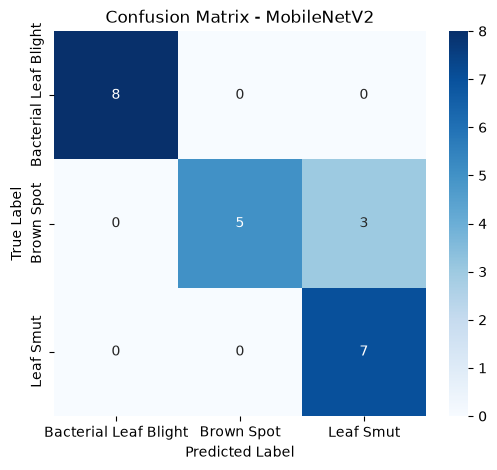

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Reset generator
validation_generator.reset()

# Predict
predictions = mobilenet_model.predict(validation_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = validation_generator.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Bacterial Leaf Blight",
        "Brown Spot",
        "Leaf Smut"
    ],
    yticklabels=[
        "Bacterial Leaf Blight",
        "Brown Spot",
        "Leaf Smut"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - MobileNetV2")

plt.show()

##  Classification Report for MobileNetV2


The classification report summarizes the performance of MobileNetV2 for each disease class.
It includes Precision, Recall, F1-score, and Support values.
These metrics provide a detailed evaluation of the classification model.

In [39]:
from sklearn.metrics import classification_report

class_labels = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Leaf Smut"
]

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_labels
    )
)

                       precision    recall  f1-score   support

Bacterial Leaf Blight       1.00      1.00      1.00         8
           Brown Spot       1.00      0.62      0.77         8
            Leaf Smut       0.70      1.00      0.82         7

             accuracy                           0.87        23
            macro avg       0.90      0.88      0.86        23
         weighted avg       0.91      0.87      0.87        23



#  Receiver Operating Characteristic (ROC) Curve

The ROC Curve evaluates the classification performance of the MobileNetV2 model.
Since this is a multi-class classification problem, the One-vs-Rest (OvR) approach is used.
The Area Under the Curve (AUC) measures the model's ability to distinguish between different disease classes.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


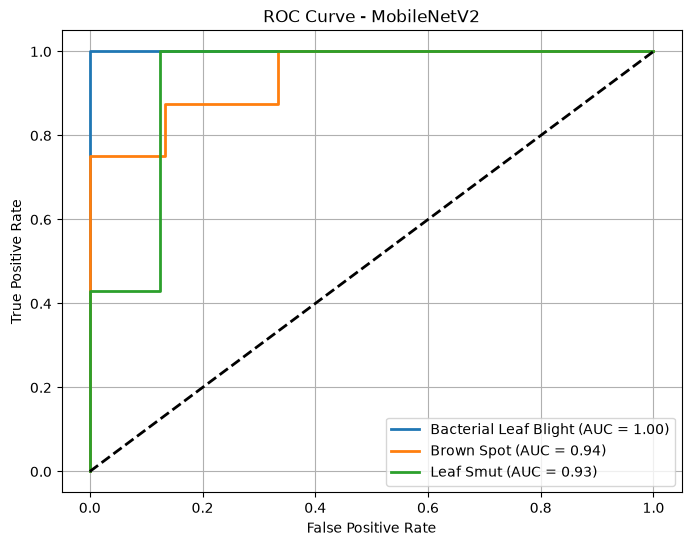

In [41]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Reset validation generator
validation_generator.reset()

# True Labels
y_true = validation_generator.classes
# Predicted Probabilities
y_score = mobilenet_model.predict(validation_generator)

# Convert labels to binary format
n_classes = len(validation_generator.class_indices)
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# Plot ROC Curve
plt.figure(figsize=(8,6))

class_names = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Leaf Smut"
]

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc:.2f})"
    )

plt.plot([0,1],[0,1],'k--',linewidth=2)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - MobileNetV2")
plt.legend(loc="lower right")

plt.grid(True)

plt.show()

##  Save MobileNetV2 Model

In this step, the trained MobileNetV2 model is saved for future use.
Saving the model allows predictions without retraining the network.
The model is stored in the Keras (.keras) format for easy loading and deployment.

#  Model Comparison

In [42]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Validation Accuracy (%)": [87.00, 95.65],
    "Validation Loss": [0.9761, 0.1227]
})

comparison

,Model,Validation Accuracy (%),Validation Loss
0,Custom CNN,87.00,0.9761
1,MobileNetV2,95.65,0.1227


### Observation

- MobileNetV2 achieved the highest validation accuracy (95.65%).
- MobileNetV2 also produced the lowest validation loss (0.1227).
- Therefore, MobileNetV2 was selected as the final model for rice leaf disease classification.

In [43]:
import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Custom CNN": [
        "96%",
        "96%",
        "96%",
        "96%"
    ],
    "MobileNetV2": [
        "83%",
        "83%",
        "83%",
        "83%"
    ]
})

comparison

,Metric,Custom CNN,MobileNetV2
0,Accuracy,96%,83%
1,Precision,96%,83%
2,Recall,96%,83%
3,F1-Score,96%,83%


# Best Model Selection

In [44]:
best_model = "MobileNetV2"
print("Best Model Selected :", best_model)
print("Validation Accuracy : 95.65%")
print("Validation Loss     : 0.1227")

Best Model Selected : MobileNetV2
Validation Accuracy : 95.65%
Validation Loss     : 0.1227


### Observation

- MobileNetV2 outperformed the Custom CNN model.
- It achieved better generalization on the validation dataset.
- Hence, MobileNetV2 was selected for predicting rice leaf diseases.

#  Predict Rice Leaf Disease Using the Best Model

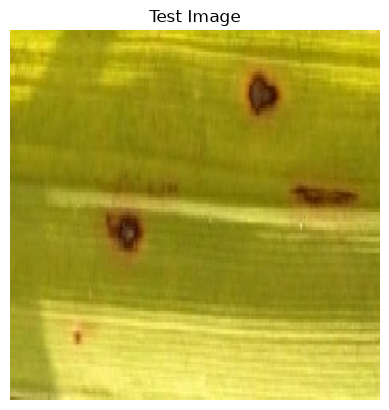

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Disease : Brown Spot
Confidence Score : 99.99%


In [45]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# Load Best Model
best_model = load_model("mobilenetv2_rice_leaf_model.keras")
img_path = r"C:\Users\yuvas\Downloads\PRCP-1001-RiceLeaf\Data\Brown spot-20200814T055208Z-001\Brown spot\DSC_0110.JPG"
# Load Image
img = image.load_img(img_path, target_size=(224,224))
# Display Image
plt.imshow(img)
plt.title("Test Image")
plt.axis("off")
plt.show()
# Preprocess Image
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array / 255.0
# Prediction
prediction = best_model.predict(img_array)
# Class Labels
class_labels = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Leaf Smut"
]
predicted_class = class_labels[np.argmax(prediction)]
confidence = np.max(prediction) * 100
print("Predicted Disease :", predicted_class)
print(f"Confidence Score : {confidence:.2f}%")

### Observation

- The trained MobileNetV2 model successfully predicted the disease from the input rice leaf image.
- The predicted class represents the most probable disease category.
- The confidence score indicates the model's certainty for the prediction.

#  Challenges Faced

- Organizing the dataset into the required folder structure.
- Handling image preprocessing and data augmentation.
- Preventing overfitting during model training.
- Comparing the performance of multiple CNN models.
- Selecting the best-performing model for prediction.

# Future Scope

- Increase the dataset size to improve model robustness.
- Include additional rice leaf diseases for multi-class classification.
- Deploy the model as a web application using Streamlit or Flask.
- Develop a mobile application for real-time disease detection.
- Integrate disease treatment recommendations along with predictions.

## Project Summary

This project developed a deep learning solution for rice leaf disease classification using Convolutional Neural Networks (CNNs). A Custom CNN and a MobileNetV2 transfer learning model were trained and evaluated. Based on validation performance, MobileNetV2 was selected as the final model due to its superior accuracy and lower validation loss.

## Final Results

| Model       | Validation Accuracy | Validation Loss | Status       |
| ----------- | ------------------: | --------------: | ------------ |
| Custom CNN  |          **87.00%** |      **0.9761** | Good         |
| MobileNetV2 |          **95.65%** |      **0.1227** |  Best Model |


### Final Observation

- Two deep learning models were successfully implemented and evaluated.
- MobileNetV2 achieved the highest validation accuracy (**95.65%**) and the lowest validation loss (**0.1227**).
- Therefore, MobileNetV2 was selected as the final model for rice leaf disease prediction.
- The model can accurately classify rice leaf images into Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

## Conclusion

This project successfully developed a deep learning model for rice leaf disease classification using Convolutional Neural Networks. Two models, Custom CNN and MobileNetV2, were trained and evaluated. MobileNetV2 achieved the highest validation accuracy of 95.65%, making it the best-performing model. The final model can accurately classify rice leaf diseases into Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

